In [1]:
import pandas as pd 

In [2]:
from sklearn.model_selection import train_test_split  

In [3]:
from sklearn.metrics import roc_auc_score

In [4]:
url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/"
    "data/course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.isna().sum()


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical = [
    'lead_source',
    'industry',
    'employment_status',
    'location'
]

numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

In [7]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [8]:
# Confirm that no missing values remain in the features
df[categorical + numerical].isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

In [9]:
# Split the data

In [10]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [11]:
# Now separate the target from the features

In [12]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [13]:
y_train = df_train['converted'].to_numpy()
y_test = df_test['converted'].to_numpy()
y_val = df_val['converted'].to_numpy()

df_train = df_train.drop(columns='converted').copy()
df_val = df_val.drop(columns='converted').copy()
df_test = df_test.drop(columns='converted').copy()

print("Training:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)

Training: (3000, 8)
Validation: (1000, 8)
Test: (1000, 8)


In [14]:
# Question 1: ROC AUC feature importance

In [15]:
roc_auc_score(y_train, df_train['lead_score'])

0.7882254810906102

In [16]:
results = []

for feature in numerical:
    scores = df_train[feature]

    original_auc = roc_auc_score(y_train, scores)

    # Reverse the ranking if the original AUC is below 0.5
    if original_auc < 0.5:
        scores = -scores

    adjusted_auc = roc_auc_score(y_train, scores)

    results.append({
        'feature': feature,
        'original_auc': original_auc,
        'adjusted_auc': adjusted_auc
    })

auc_results = pd.DataFrame(results)

auc_results = auc_results.sort_values(
    'adjusted_auc',
    ascending=False
)

print(auc_results.to_string(index=False))

                 feature  original_auc  adjusted_auc
              lead_score      0.788225      0.788225
       interaction_count      0.764920      0.764920
number_of_courses_viewed      0.722989      0.722989
           annual_income      0.608198      0.608198


In [17]:
# Question 2: Training the model

In [18]:
train_dicts = df_train[categorical + numerical].to_dict(
    orient='records'
)

val_dicts = df_val[categorical + numerical].to_dict(
    orient='records'
)

In [19]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)


In [20]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("Missing targets:", pd.isna(y_train).sum())
print("Target values:", pd.Series(y_train).unique())

X_train shape: (3000, 28)
y_train shape: (3000,)
Missing targets: 0
Target values: [1 0]


In [21]:
import numpy as np

# Works with sparse or dense X_train
values = X_train.data if hasattr(X_train, 'toarray') else X_train

print("Missing feature values:", np.isnan(values).sum())
print("Infinite feature values:", np.isinf(values).sum())

Missing feature values: 0
Infinite feature values: 0


In [22]:
from sklearn.linear_model import LogisticRegression

# Create ordinary numerical arrays instead of sparse matrices
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Keep the homework's exact model settings
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

# Predict conversion probabilities and evaluate
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f"Validation ROC AUC: {auc:.3f}")

Validation ROC AUC: 0.732


In [23]:
# Recall, Precision 

In [24]:

from sklearn.metrics import precision_score, recall_score

# 0.00, 0.01, 0.02, ..., 1.00
thresholds = np.linspace(0, 1, 101)

results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    predicted_positive = y_pred >= threshold

    precision = precision_score(
        y_val,
        predicted_positive,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predicted_positive,
        zero_division=0
    )

    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall
    })

df_scores = pd.DataFrame(results)

df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


In [25]:
# Plotting 

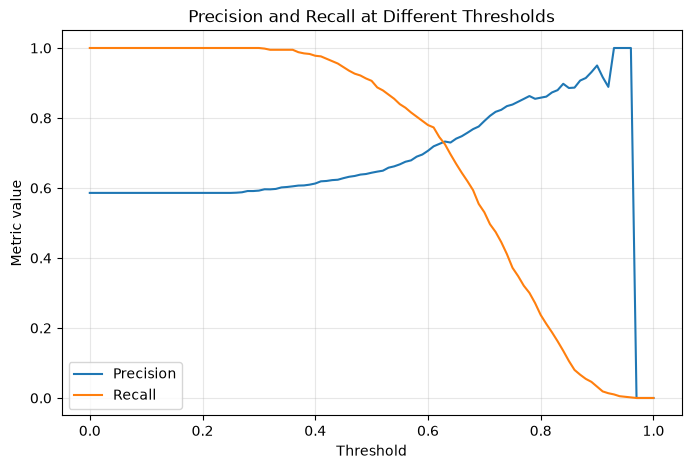

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    df_scores['threshold'],
    df_scores['precision'],
    label='Precision'
)

plt.plot(
    df_scores['threshold'],
    df_scores['recall'],
    label='Recall'
)

plt.xlabel('Threshold')
plt.ylabel('Metric value')
plt.title('Precision and Recall at Different Thresholds')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [27]:
valid_scores = df_scores.loc[
    (df_scores['precision'] != 0) |
    (df_scores['recall'] != 0)
].copy()

valid_scores['difference'] = (
    valid_scores['precision'] - valid_scores['recall']
).abs()

best_index = valid_scores['difference'].idxmin()

best_row = valid_scores.loc[best_index]

print(f"Threshold: {best_row['threshold']:.2f}")
print(f"Precision: {best_row['precision']:.3f}")
print(f"Recall: {best_row['recall']:.3f}")
print(f"Absolute difference: {best_row['difference']:.4f}")

Threshold: 0.63
Precision: 0.733
Recall: 0.725
Absolute difference: 0.0075


In [28]:
# At which threshold is the F1 score highest?

In [29]:
# Default to 0 when precision + recall is 0
df_scores['f1'] = 0.0

denominator = df_scores['precision'] + df_scores['recall']

valid = denominator > 0

df_scores.loc[valid, 'f1'] = (
    2
    * df_scores.loc[valid, 'precision']
    * df_scores.loc[valid, 'recall']
    / denominator.loc[valid]
)

# Find the row with the highest F1
best_index = df_scores['f1'].idxmax()
best_row = df_scores.loc[best_index]

print(f"Best threshold: {best_row['threshold']:.2f}")
print(f"Precision: {best_row['precision']:.3f}")
print(f"Recall: {best_row['recall']:.3f}")
print(f"F1: {best_row['f1']:.3f}")

Best threshold: 0.41
Precision: 0.619
Recall: 0.976
F1: 0.758


In [30]:
# 5-Fold CV
from sklearn.model_selection import KFold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for fold, (train_idx, val_idx) in enumerate(
    kfold.split(df_full_train),
    start=1
):
    # Select this fold's training and validation rows
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]

    # Extract the actual outcomes
    y_fold_train = fold_train['converted'].to_numpy()
    y_fold_val = fold_val['converted'].to_numpy()

    # Select input features only
    train_dicts = fold_train[
        categorical + numerical
    ].to_dict(orient='records')

    val_dicts = fold_val[
        categorical + numerical
    ].to_dict(orient='records')

    # Fit a fresh vectorizer on this fold's training data
    dv_fold = DictVectorizer(sparse=False)

    X_fold_train = dv_fold.fit_transform(train_dicts)
    X_fold_val = dv_fold.transform(val_dicts)

    # Train a fresh model
    model_fold = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_fold_train, y_fold_train)

    # Evaluate on this fold's validation data
    y_fold_pred = model_fold.predict_proba(X_fold_val)[:, 1]

    auc = roc_auc_score(y_fold_val, y_fold_pred)

    scores.append(auc)

    print(f"Fold {fold}: AUC = {auc:.6f}")

Fold 1: AUC = 0.730560
Fold 2: AUC = 0.729573
Fold 3: AUC = 0.736343
Fold 4: AUC = 0.741245
Fold 5: AUC = 0.720914


In [31]:
mean_auc = np.mean(scores)
std_auc = np.std(scores)

print(f"\nMean AUC: {mean_auc:.3f}")
print(f"Standard deviation: {std_auc:.3f}")


Mean AUC: 0.732
Standard deviation: 0.007


In [32]:
# Q6 

In [33]:
C_values = [0.000001, 0.001, 1]

tuning_results = []

for C in C_values:

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        y_fold_train = fold_train['converted'].to_numpy()
        y_fold_val = fold_val['converted'].to_numpy()

        train_dicts = fold_train[
            categorical + numerical
        ].to_dict(orient='records')

        val_dicts = fold_val[
            categorical + numerical
        ].to_dict(orient='records')

        dv_fold = DictVectorizer(sparse=False)

        X_fold_train = dv_fold.fit_transform(train_dicts)
        X_fold_val = dv_fold.transform(val_dicts)

        model_fold = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_fold_train, y_fold_train)

        y_fold_pred = model_fold.predict_proba(
            X_fold_val
        )[:, 1]

        auc = roc_auc_score(y_fold_val, y_fold_pred)

        scores.append(auc)

    tuning_results.append({
        'C': C,
        'mean_auc': np.mean(scores),
        'std_auc': np.std(scores)
    })

    print(
        f"C={C:g}: "
        f"mean AUC={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
